In [1]:
# Importing required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Paths
train = pd.read_csv(r"data/student_dataset.csv")
test = pd.read_csv(r"data/test.csv")
sample_sub = pd.read_csv(r"data/sample_submission.csv")

# Shape of data
print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_sub.shape)


Train shape: (16000, 13)
Test shape: (4000, 12)
Sample submission shape: (4000, 2)


In [3]:
train.head()

,unit_id,unit_type,ambient_temp,process_temp,coolant_flow,shaft_speed,drive_torque,power_load,component_wear,thermal_stress,mechanical_load,vibration_index,condition
0,UNT-184174,M,21.5,56.4,17.85,1454.0,58.2,9.099,30.0,29.31,57.19,1.768,0
1,UNT-236234,H,29.9,65.0,30.88,1720.0,54.6,10.101,13.0,23.93,36.94,1.081,0
2,UNT-247460,M,26.4,47.8,19.75,1552.0,38.4,6.328,89.0,13.52,38.22,1.031,0
3,UNT-176316,M,28.8,60.9,19.10,1513.0,49.1,7.768,59.0,24.62,46.17,1.011,0
4,UNT-105110,S,29.4,64.0,11.77,1536.0,52.6,8.405,36.0,27.83,94.72,1.851,1


In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16000 entries, 0 to 15999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   unit_id          16000 non-null  object 
 1   unit_type        15978 non-null  object 
 2   ambient_temp     15953 non-null  float64
 3   process_temp     15955 non-null  float64
 4   coolant_flow     15939 non-null  float64
 5   shaft_speed      15968 non-null  float64
 6   drive_torque     15964 non-null  float64
 7   power_load       15975 non-null  float64
 8   component_wear   15944 non-null  float64
 9   thermal_stress   15950 non-null  float64
 10  mechanical_load  15955 non-null  float64
 11  vibration_index  15926 non-null  float64
 12  condition        16000 non-null  int64  
dtypes: float64(10), int64(1), object(2)
memory usage: 1.6+ MB


In [5]:
# Check for missing values
missing = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_missing_%": (train.isna().mean() * 100).round(2),
    "test_missing": test.isna().sum(),
    "test_missing_%": (test.isna().mean() * 100).round(2),
})
print(missing)

                 train_missing  train_missing_%  test_missing  test_missing_%
ambient_temp                47             0.29          10.0            0.25
component_wear              56             0.35          15.0            0.38
condition                    0             0.00           NaN             NaN
coolant_flow                61             0.38          12.0            0.30
drive_torque                36             0.22          12.0            0.30
mechanical_load             45             0.28           3.0            0.08
power_load                  25             0.16           8.0            0.20
process_temp                45             0.28          13.0            0.32
shaft_speed                 32             0.20           8.0            0.20
thermal_stress              50             0.31          16.0            0.40
unit_id                      0             0.00           0.0            0.00
unit_type                   22             0.14          11.0   

In [6]:
# Label Encode the unit_type feature because it is object datatype

type_map = {"S": 0, "M": 1, "H": 2}

train["unit_type"] = train["unit_type"].map(type_map)
test["unit_type"] = test["unit_type"].map(type_map)

In [7]:
# Mean Imputer to fill the missing values

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# All model input columns (exclude id and target)
feature_cols = [
    c for c in train.columns
    if c not in ["unit_id", "condition"]
]

train_raw = train.copy()
test_raw = test.copy()

# 1. Scale
scaler_imp = StandardScaler()
train_scaled = scaler_imp.fit_transform(train[feature_cols])
test_scaled = scaler_imp.transform(test[feature_cols])

# 2. Impute using the mean of each feature
mean_imp = SimpleImputer(strategy="mean")
train_imputed = mean_imp.fit_transform(train_scaled)
test_imputed = mean_imp.transform(test_scaled)

# 3. Convert back to original units
train[feature_cols] = scaler_imp.inverse_transform(train_imputed)
test[feature_cols] = scaler_imp.inverse_transform(test_imputed)

# 4. Restore categorical integer values
train["unit_type"] = train["unit_type"].round().clip(0, 2).astype(int)
test["unit_type"] = test["unit_type"].round().clip(0, 2).astype(int)

# 5. Verify
print("Missing values in train:", train[feature_cols].isna().sum().sum())
print("Missing values in test:", test[feature_cols].isna().sum().sum())


Missing values in train: 0
Missing values in test: 0


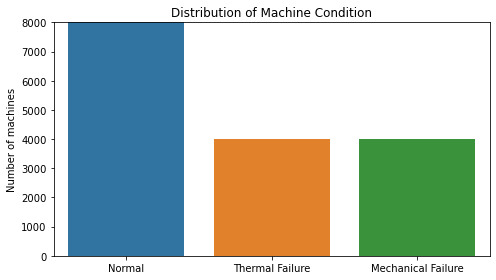

In [8]:
# Target Distribution

class_names = {0: "Normal", 1: "Thermal Failure", 2: "Mechanical Failure"}
counts = train["condition"].value_counts()
percents = (counts / counts.sum() * 100).round(1)

plt.figure(figsize=(7, 4))
ax = sns.barplot(x=[class_names[i] for i in counts.index], y=counts.values)

plt.title("Distribution of Machine Condition")
plt.ylabel("Number of machines")
plt.ylim(0, counts.max())
plt.tight_layout()
plt.show()


                   count     mean     std     min      25%      50%      75%  \
ambient_temp     16000.0    25.98    4.92   12.00    22.30    24.90    29.90   
process_temp     16000.0    60.99   11.08   33.60    52.90    59.80    67.60   
coolant_flow     16000.0    17.88    6.10    7.82    12.39    17.67    22.11   
shaft_speed      16000.0  1519.40  262.39  824.00  1324.75  1496.50  1692.00   
drive_torque     16000.0    55.03   11.44   25.10    46.80    54.10    62.32   
power_load       16000.0     8.96    3.13    2.75     6.62     8.45    10.81   
component_wear   16000.0   108.33   67.23    3.00    58.00    94.00   144.00   
thermal_stress   16000.0    27.67   10.79    7.36    19.68    25.78    33.72   
mechanical_load  16000.0    72.48   24.20   25.49    53.53    68.18    88.81   
vibration_index  16000.0     1.69    0.49    0.61     1.34     1.62     1.96   

                     max  
ambient_temp       41.20  
process_temp      116.90  
coolant_flow       37.14  
shaft_speed

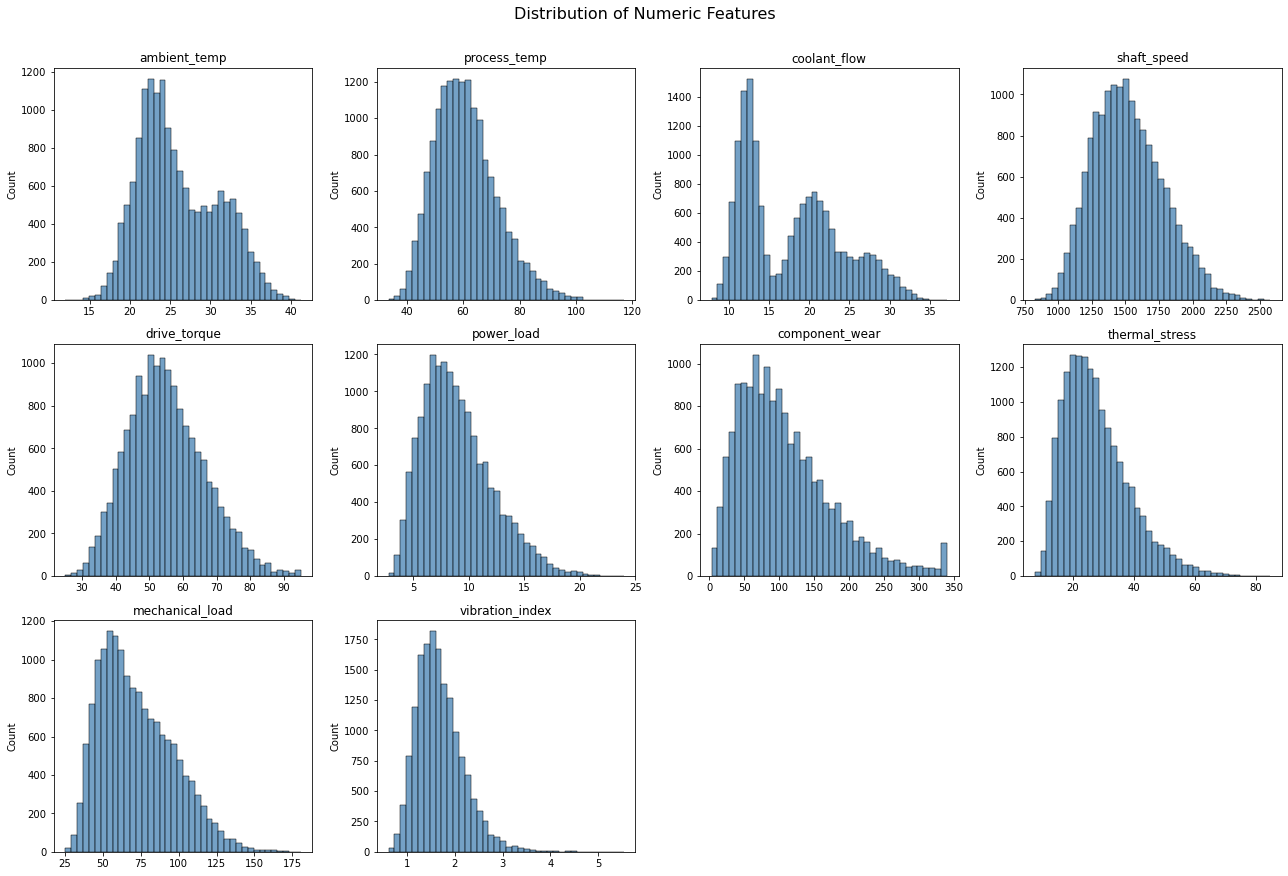

In [9]:
# Feature Distributions
feature_cols = [c for c in train.columns if c not in ["unit_id", "condition"]]
num_cols = [c for c in feature_cols if c != "unit_type"]

print(train[num_cols].describe().T.round(2))

# Histogram of each numeric feature
n_cols = 4
n_rows = int(np.ceil(len(num_cols) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(train[col], bins=40, ax=axes[i], color="steelblue")
    axes[i].set_title(f"{col}")
    axes[i].set_xlabel("")

# Hide any empty subplot boxes
for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribution of Numeric Features", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

,feature,Q1,Q3,IQR,lower_bound,upper_bound,n_outliers,outlier_%,failure_%_among_outliers
6,component_wear,58.000,144.000,86.000,-71.000,273.000,459,2.87,98.7
9,vibration_index,1.338,1.962,0.624,0.402,2.898,343,2.14,93.0
7,thermal_stress,19.680,33.720,14.040,-1.380,54.780,338,2.11,100.0
5,power_load,6.622,10.811,4.189,0.338,17.095,230,1.44,100.0
1,process_temp,52.900,67.600,14.700,30.850,89.650,222,1.39,100.0
4,drive_torque,46.800,62.325,15.525,23.512,85.612,136,0.85,100.0
3,shaft_speed,1324.750,1692.000,367.250,773.875,2242.875,93,0.58,100.0
8,mechanical_load,53.528,88.812,35.285,0.600,141.740,92,0.57,100.0
2,coolant_flow,12.390,22.110,9.720,-2.190,36.690,1,0.01,0.0
0,ambient_temp,22.300,29.900,7.600,10.900,41.300,0,0.00,NaN


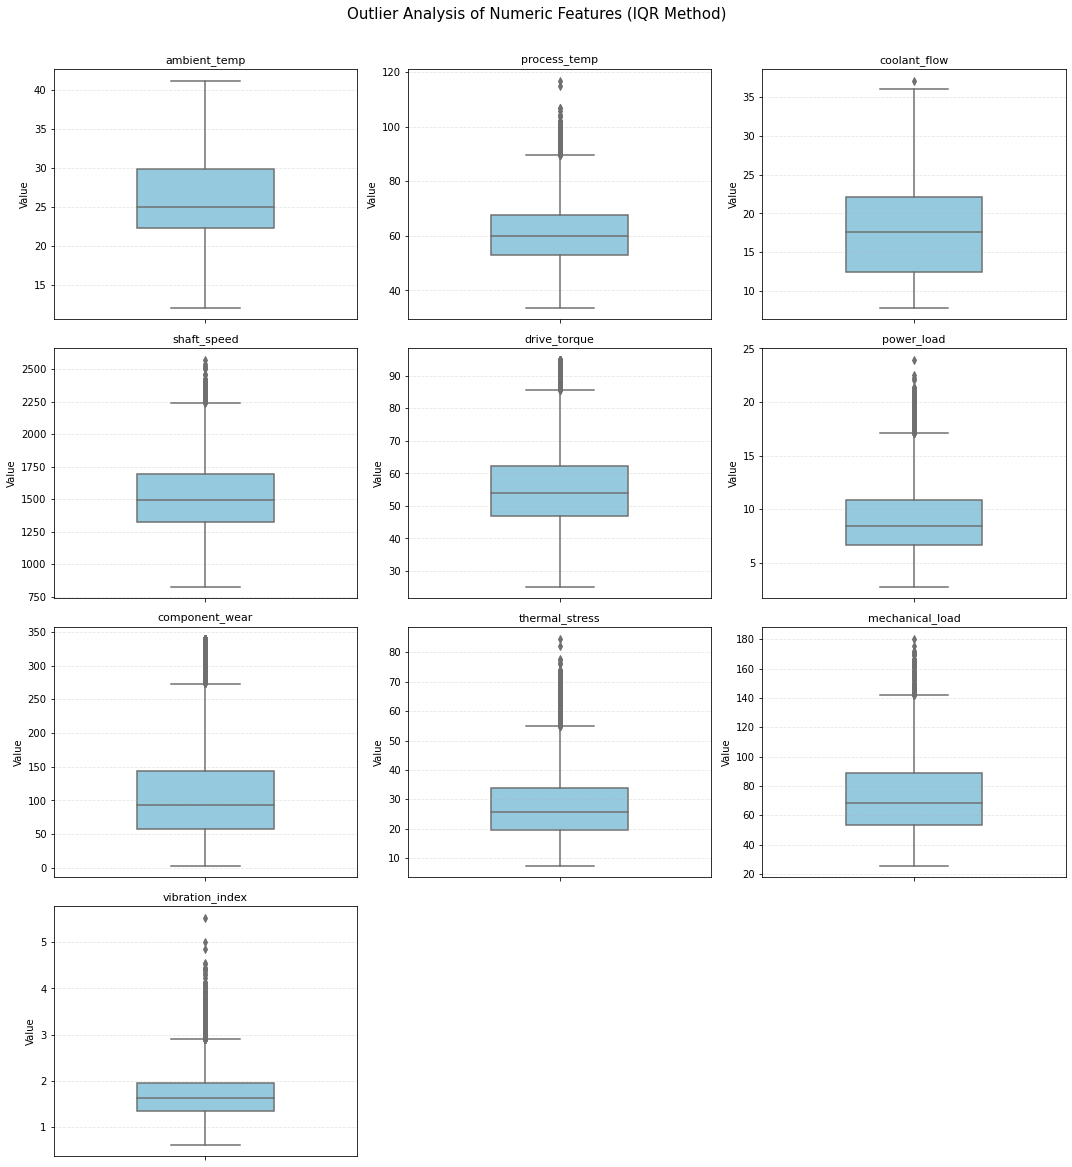

In [10]:

# ============================================================
# EDA: OUTLIER DETECTION USING IQR
# Method: Q1 - 1.5*IQR and Q3 + 1.5*IQR
# Decision: Keep outliers because extreme readings may indicate
#           machine failures.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import iqr

# --- Count outliers per feature using scipy's IQR function ---
outlier_summary = []

for col in num_cols:
    q1 = train[col].quantile(0.25)
    q3 = train[col].quantile(0.75)

    # Calculate IQR using SciPy
    iqr_value = iqr(train[col].dropna(), nan_policy="omit")

    lower = q1 - 1.5 * iqr_value
    upper = q3 + 1.5 * iqr_value

    mask = (train[col] < lower) | (train[col] > upper)

    n_outliers = mask.sum()

    fail_share = (
        (train.loc[mask, "condition"] != 0).mean() * 100
        if n_outliers > 0 else np.nan
    )

    outlier_summary.append([
        col,
        round(q1, 3),
        round(q3, 3),
        round(iqr_value, 3),
        round(lower, 3),
        round(upper, 3),
        n_outliers,
        round(mask.mean() * 100, 2),
        round(fail_share, 1)
    ])

outlier_df = pd.DataFrame(
    outlier_summary,
    columns=[
        "feature", "Q1", "Q3", "IQR",
        "lower_bound", "upper_bound",
        "n_outliers", "outlier_%", "failure_%_among_outliers"
    ]
)

display(outlier_df.sort_values("n_outliers", ascending=False))


# --- Vertical boxplots in a multi-panel layout ---
n_features = len(num_cols)
n_cols_plot = 3
n_rows_plot = int(np.ceil(n_features / n_cols_plot))

fig, axes = plt.subplots(
    n_rows_plot,
    n_cols_plot,
    figsize=(15, 4 * n_rows_plot)
)

axes = np.array(axes).reshape(-1)

for i, col in enumerate(num_cols):
    sns.boxplot(
        y=train[col],
        ax=axes[i],
        color="skyblue",
        width=0.45,
        showfliers=True
    )

    axes[i].set_title(f"{col}", fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Value")
    axes[i].grid(axis="y", linestyle="--", alpha=0.3)

# Hide unused subplot positions
for j in range(n_features, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Outlier Analysis of Numeric Features (IQR Method)",
    fontsize=15,
    y=1.01
)

plt.tight_layout()
plt.show()


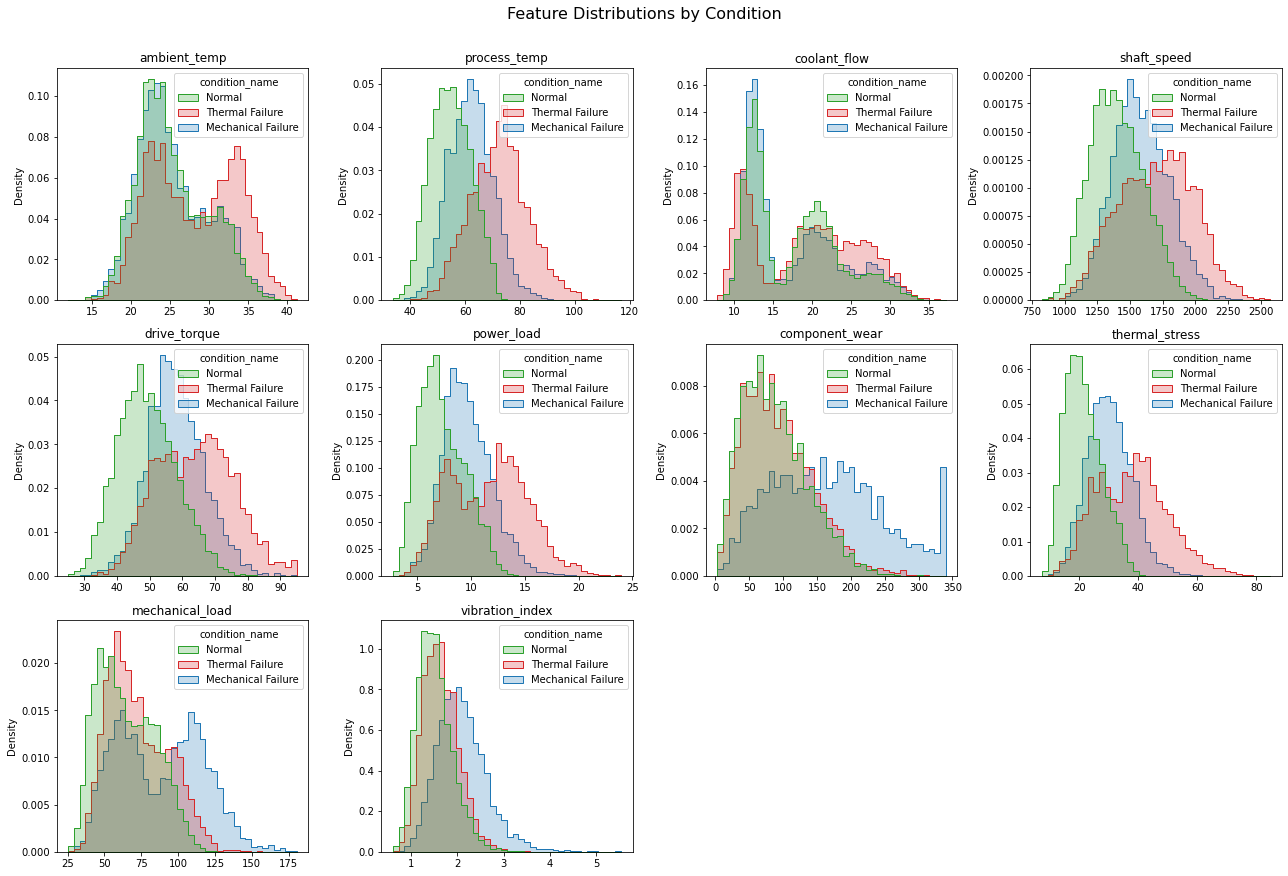

TypeError: boxplot() got an unexpected keyword argument 'legend'

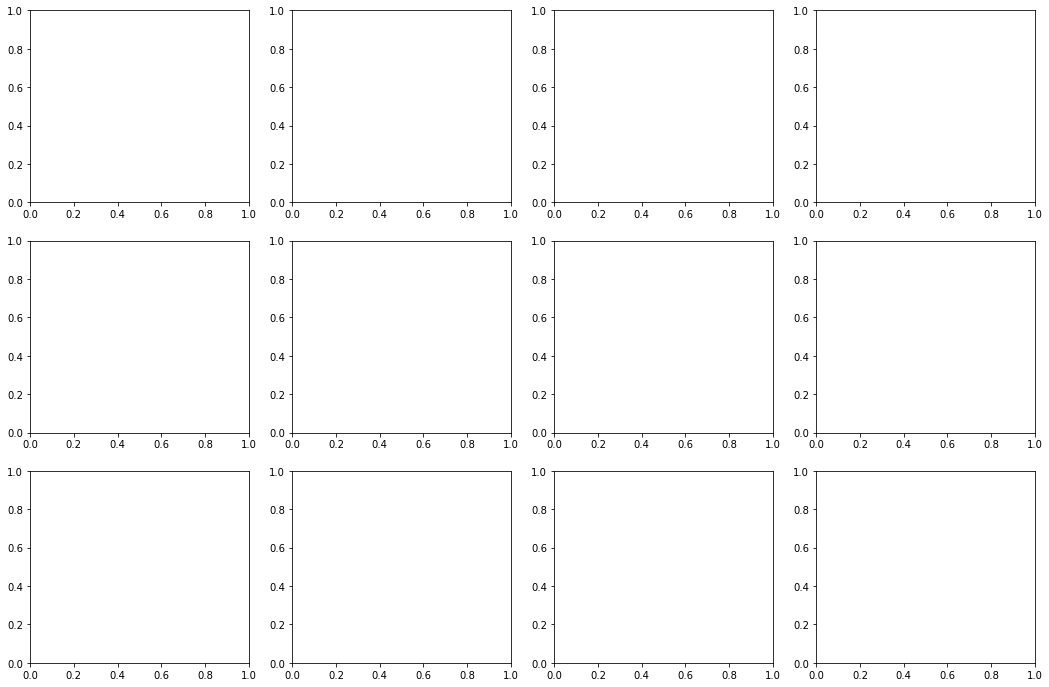

In [11]:
# Features VS Condition
# Why it matters: features whose distributions differ clearly
#   between classes are the most useful for the model.
#
# stat="density" + common_norm=False: each class is scaled on its own,
#   so the smaller failure classes (4000 each) aren't hidden by
#   the larger Normal class (8000) and their shapes can be compared fairly.

# Plotting copy with readable class names (keeps train itself unchanged,
# so this text column never ends up in the model features)
plot_df = train.copy()
plot_df["condition_name"] = plot_df["condition"].map(class_names)

order = ["Normal", "Thermal Failure", "Mechanical Failure"]
palette = {"Normal": "tab:green", "Thermal Failure": "tab:red",
           "Mechanical Failure": "tab:blue"}

# 4a. Histplot of each numeric feature, coloured by condition
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(data=plot_df, x=col, hue="condition_name", hue_order=order,
                 bins=40, stat="density", common_norm=False, element="step",
                 palette=palette, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Feature Distributions by Condition", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

# 4b. Boxplot of each numeric feature by condition
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(data=plot_df, x="condition_name", y=col, order=order,
                hue="condition_name", hue_order=order, palette=palette,
                legend=False, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", labelsize=8)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Boxplots of Features by Condition", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

# 4c. Median of each feature per class (numbers behind the plots)
median_by_class = plot_df.groupby("condition_name")[num_cols].median().T[order].round(2)
display(median_by_class)

# 4d. unit_type vs condition (categorical, so a % table instead of histplot)
type_ct = pd.crosstab(plot_df["unit_type"].map({0: "S", 1: "M", 2: "H"}),
                      plot_df["condition_name"], normalize="index")[order] * 100
display(type_ct.round(1))

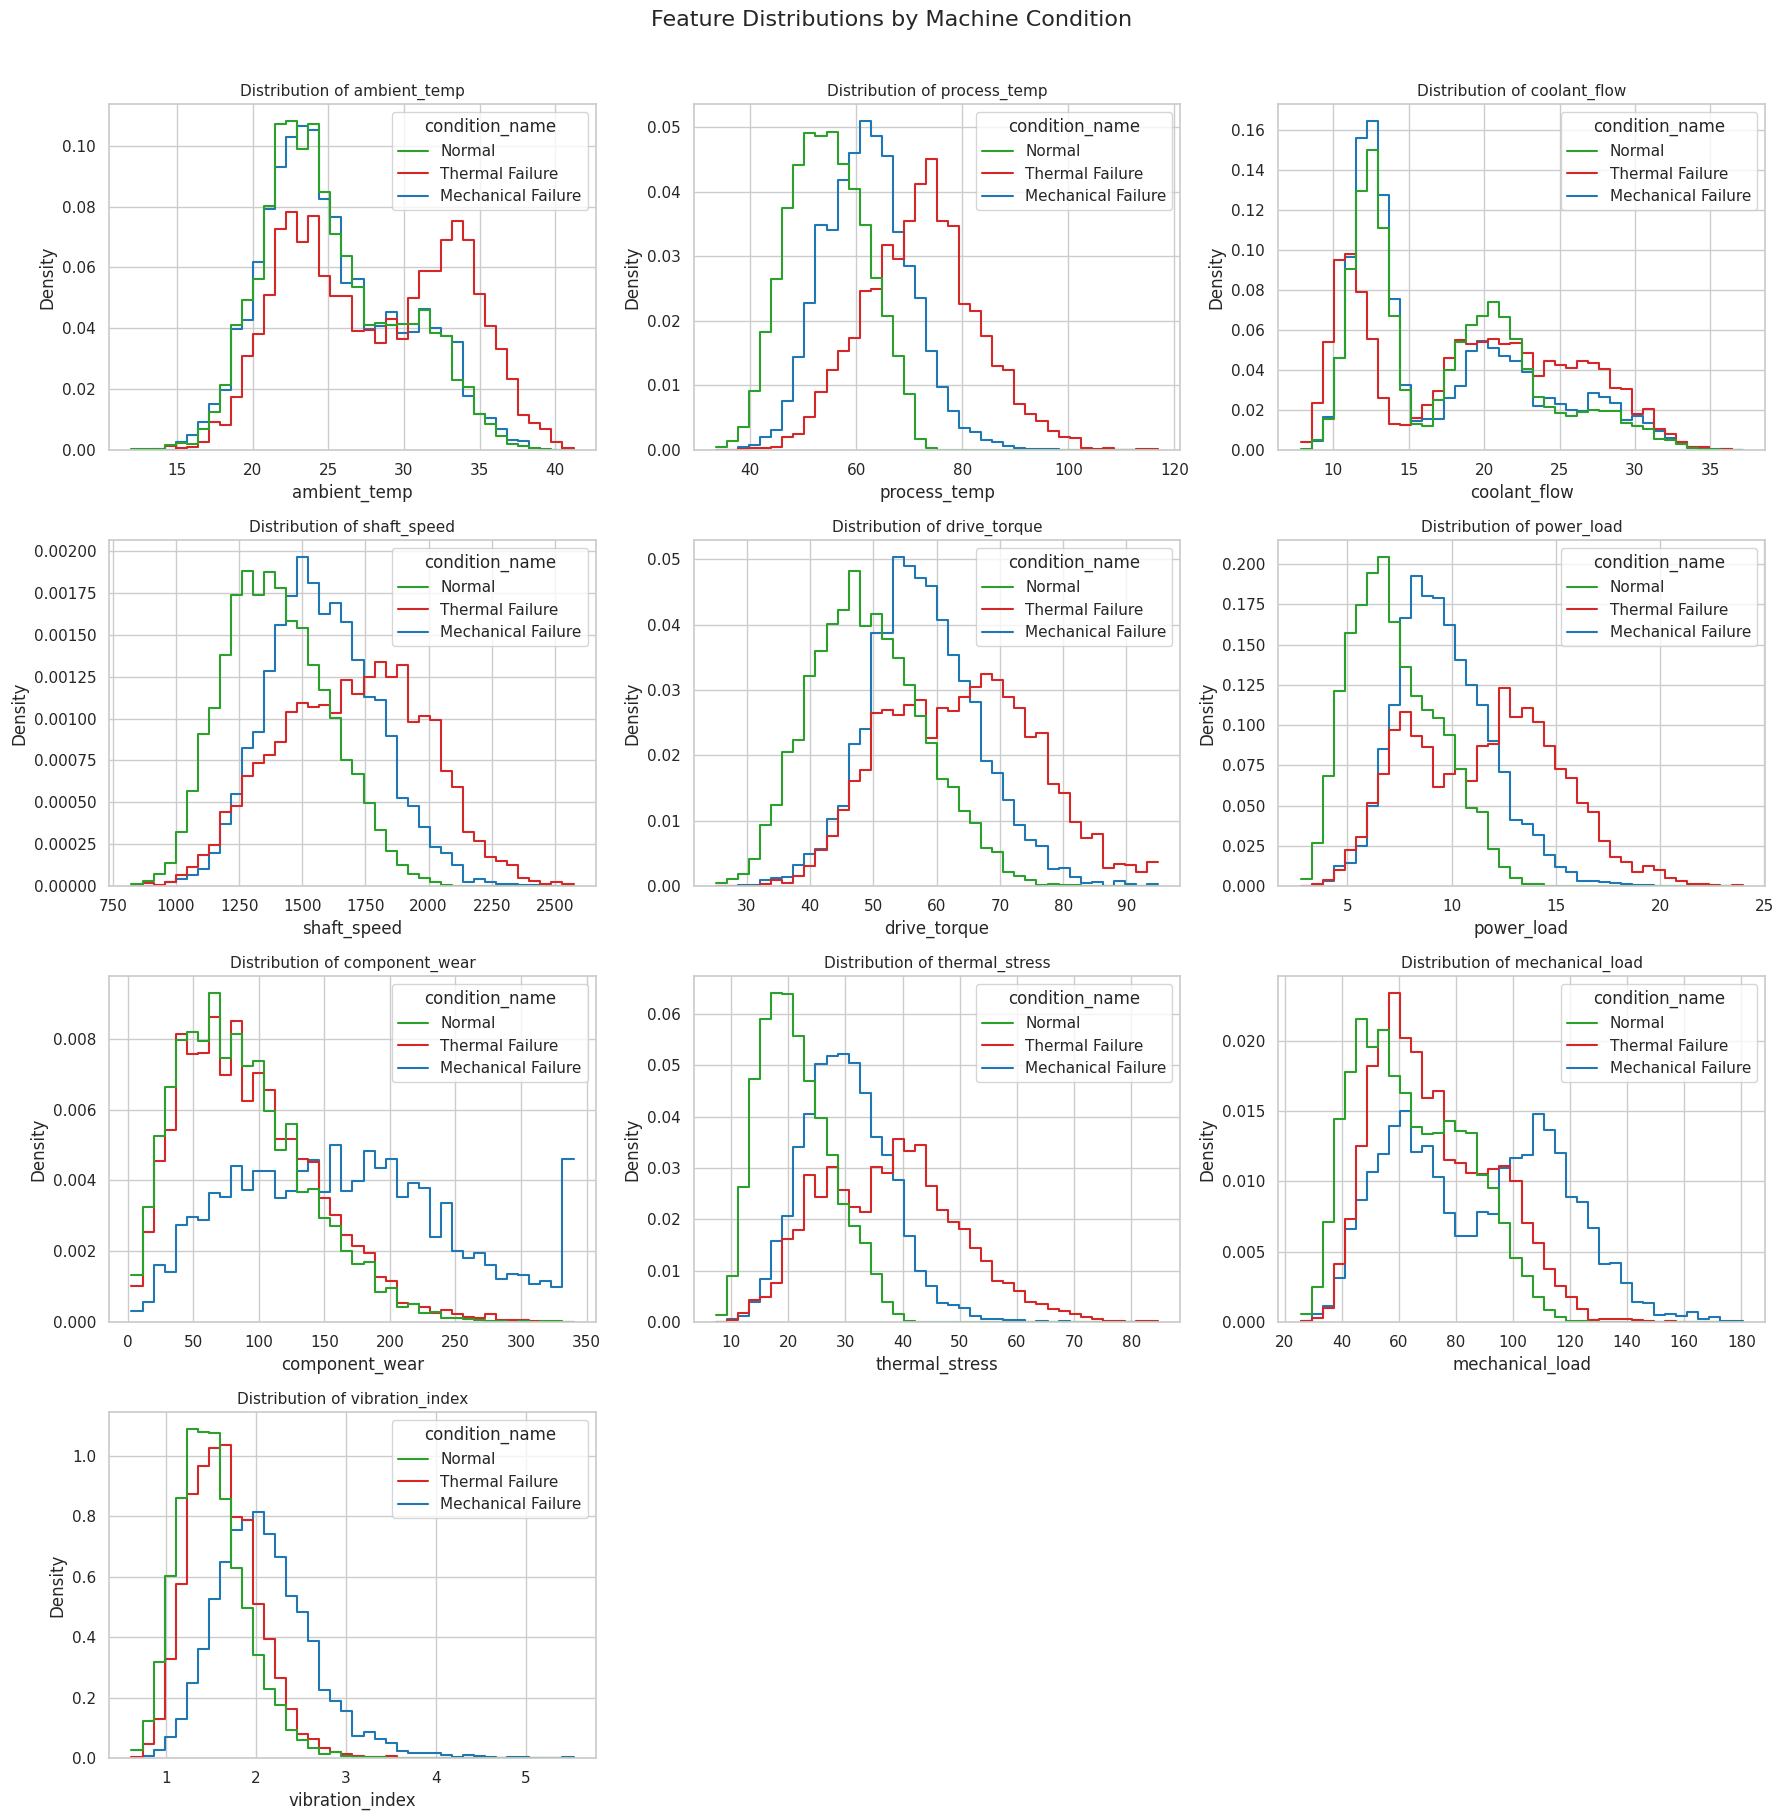

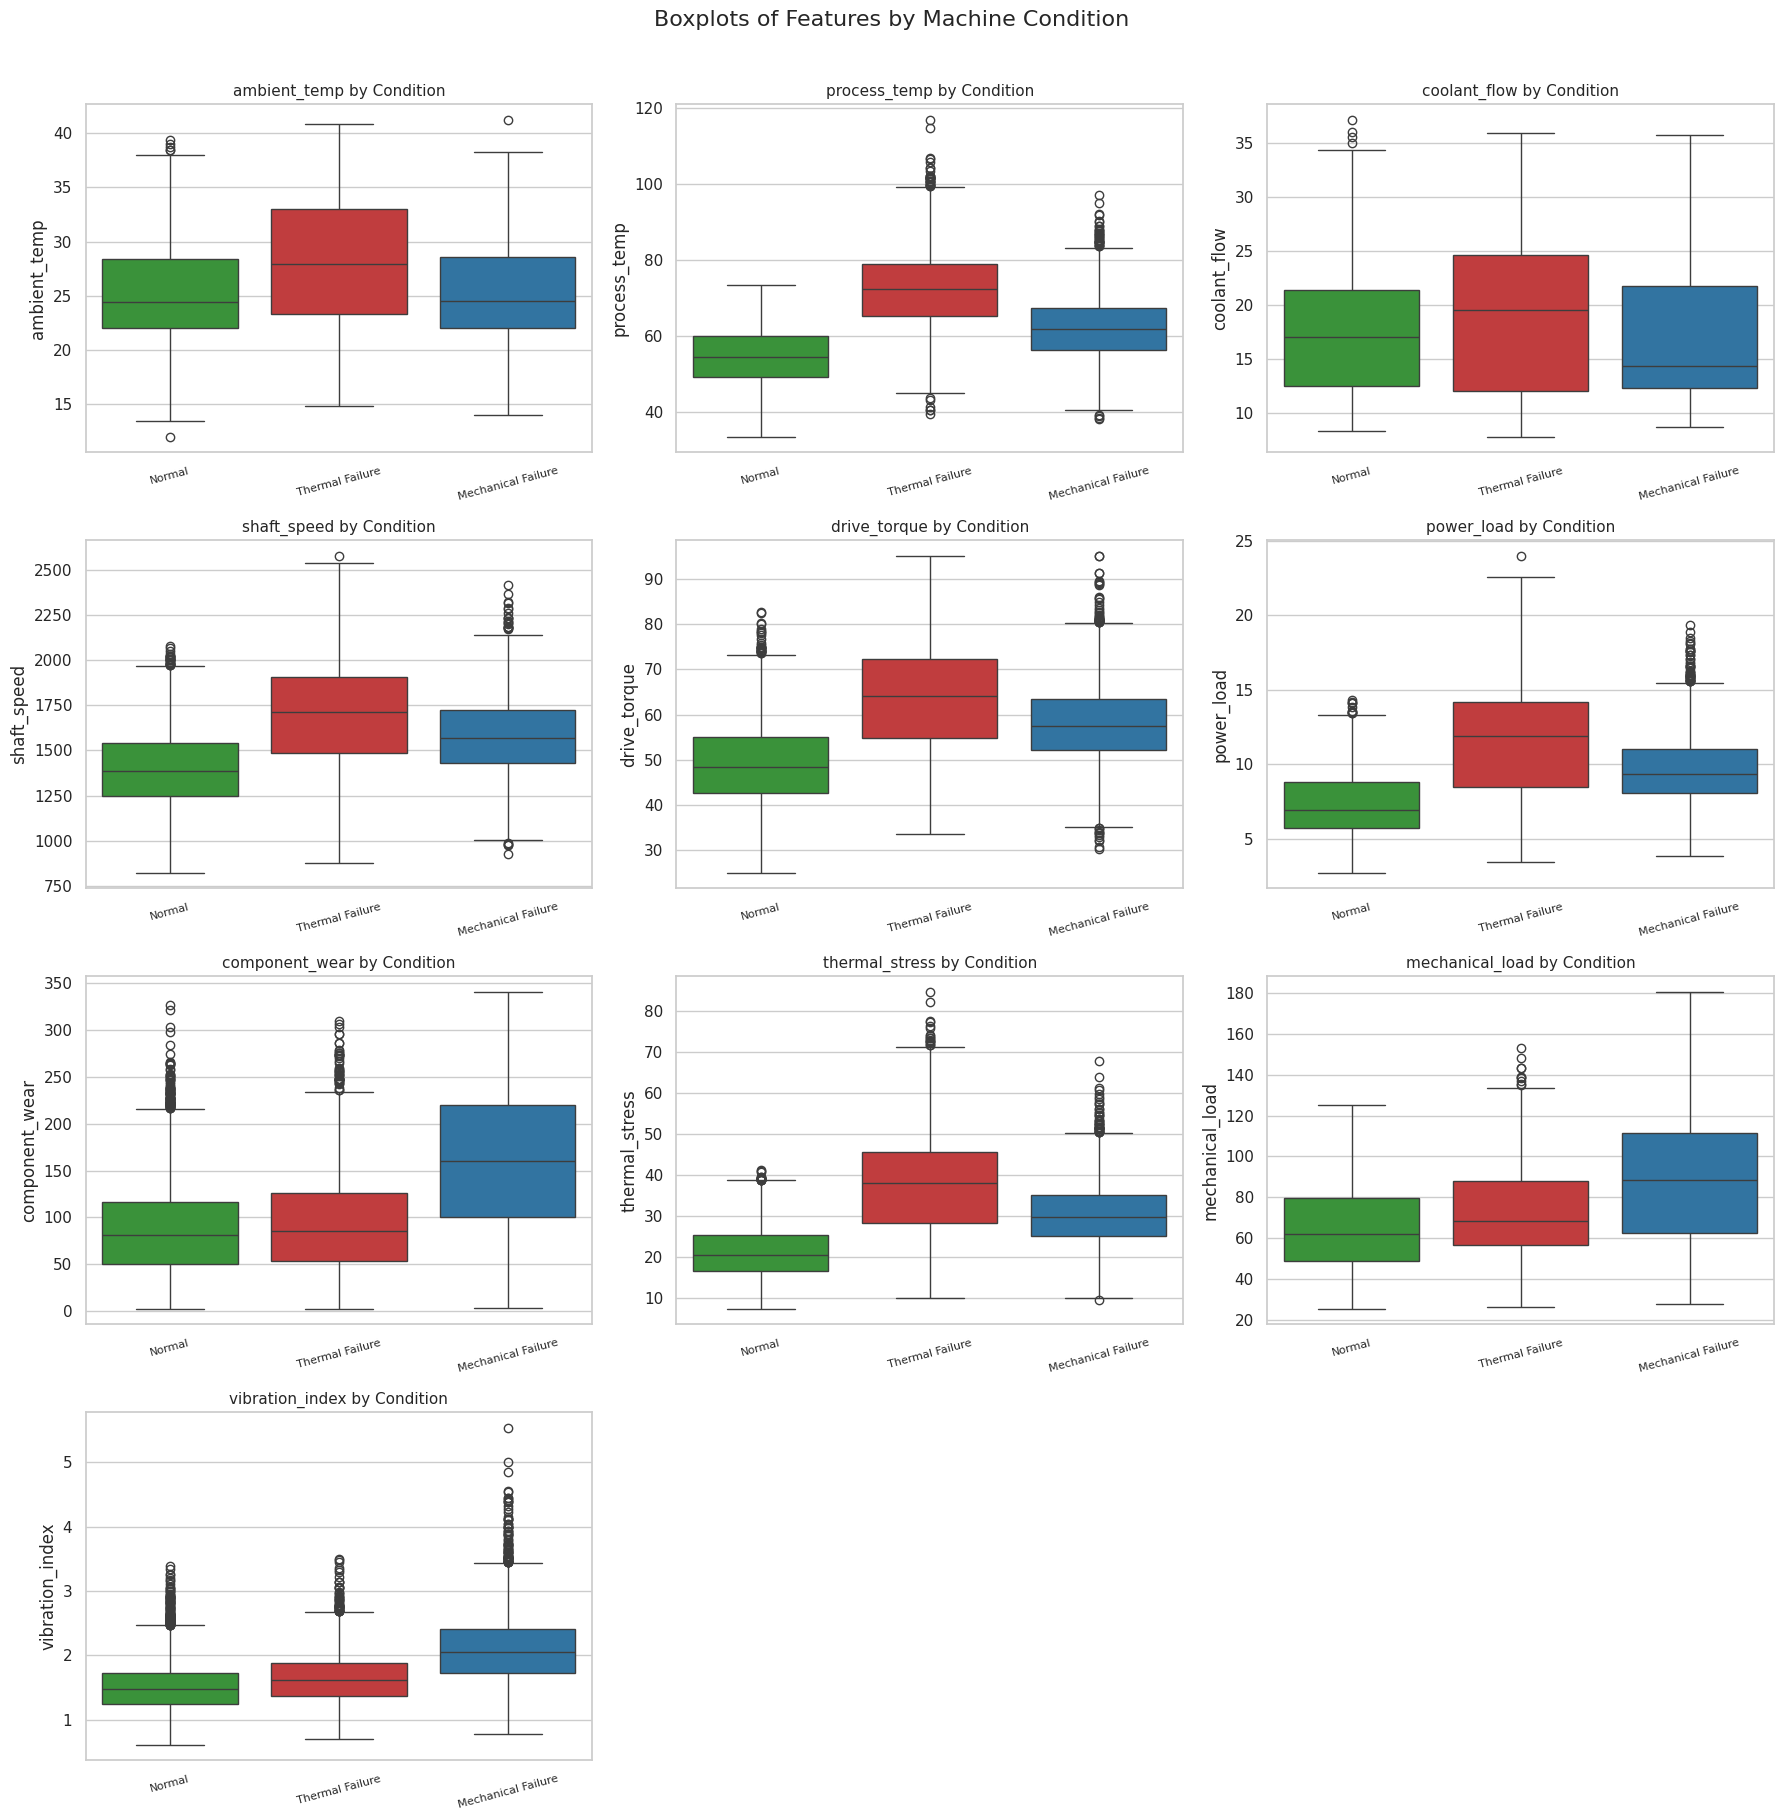

Median values of each numeric feature by condition:


condition_name,Normal,Thermal Failure,Mechanical Failure
ambient_temp,24.40,27.90,24.50
process_temp,54.50,72.50,61.90
coolant_flow,17.08,19.56,14.34
shaft_speed,1385.00,1710.50,1567.00
drive_torque,48.50,64.20,57.40
power_load,6.96,11.87,9.39
component_wear,81.00,86.00,160.00
thermal_stress,20.56,38.02,29.75
mechanical_load,61.96,68.48,88.49
vibration_index,1.47,1.61,2.04


Condition percentages within each unit type (%):


condition_name,Normal,Thermal Failure,Mechanical Failure
unit_type,,,
H,35.3,42.4,22.2
M,55.4,23.8,20.9
S,52.4,18.2,29.4


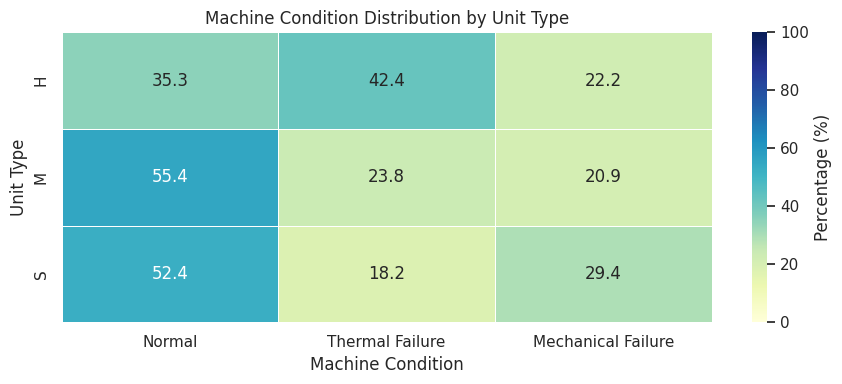

In [ ]:

# ============================================================
# FEATURES VS CONDITION
# 4a. Feature distributions by condition
# 4b. Boxplots by condition
# 4c. Median of each feature per class
# 4d. unit_type vs condition percentage table
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure plots display in Kaggle notebooks
%matplotlib inline

# --- Prepare plotting data (train remains unchanged) ---
plot_df = train.copy()
plot_df["condition_name"] = plot_df["condition"].map(class_names)

order = ["Normal", "Thermal Failure", "Mechanical Failure"]

palette = {
    "Normal": "tab:green",
    "Thermal Failure": "tab:red",
    "Mechanical Failure": "tab:blue"
}

# Number of subplot rows and columns
n_features = len(num_cols)
n_cols_plot = 3
n_rows_plot = int(np.ceil(n_features / n_cols_plot))

sns.set_theme(style="whitegrid", context="notebook")


# ============================================================
# 4a. FEATURE DISTRIBUTIONS BY CONDITION
# Overlaid histograms with independent density normalization
# ============================================================

fig, axes = plt.subplots(
    n_rows_plot,
    n_cols_plot,
    figsize=(18, 4.5 * n_rows_plot),
    squeeze=False
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.histplot(
        data=plot_df,
        x=col,
        hue="condition_name",
        hue_order=order,
        bins=40,
        stat="density",
        common_norm=False,
        element="step",
        fill=False,
        palette=palette,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {col}", fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Density")

for j in range(n_features, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Feature Distributions by Machine Condition",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()


# ============================================================
# 4b. BOXPLOTS OF FEATURES BY CONDITION
# Shows median, IQR, whiskers and outliers
# ============================================================

fig, axes = plt.subplots(
    n_rows_plot,
    n_cols_plot,
    figsize=(18, 4.5 * n_rows_plot),
    squeeze=False
)

axes = axes.flatten()

for i, col in enumerate(num_cols):
    sns.boxplot(
        data=plot_df,
        x="condition_name",
        y=col,
        hue="condition_name",
        order=order,
        hue_order=order,
        palette=palette,
        dodge=False,
        legend=False,
        showfliers=True,
        ax=axes[i]
    )

    axes[i].set_title(f"{col} by Condition", fontsize=11)
    axes[i].set_xlabel("")
    axes[i].set_ylabel(col)
    axes[i].tick_params(axis="x", rotation=15, labelsize=8)

for j in range(n_features, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    "Boxplots of Features by Machine Condition",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()


# ============================================================
# 4c. MEDIAN OF EACH FEATURE PER CLASS
# ============================================================

median_by_class = (
    plot_df.groupby("condition_name")[num_cols]
    .median()
    .T
    .reindex(columns=order)
    .round(2)
)

print("Median values of each numeric feature by condition:")
display(median_by_class)


# ============================================================
# 4d. UNIT_TYPE VS CONDITION
# Row-wise percentages: condition distribution within each type
# ============================================================

type_ct = pd.crosstab(
    plot_df["unit_type"].map({0: "S", 1: "M", 2: "H"}),
    plot_df["condition_name"],
    normalize="index"
).reindex(columns=order, fill_value=0) * 100

type_ct = type_ct.round(1)

print("Condition percentages within each unit type (%):")
display(type_ct)

# Optional: visualize the percentage table as a heatmap
plt.figure(figsize=(9, 4))

sns.heatmap(
    type_ct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Percentage (%)"}
)

plt.title("Machine Condition Distribution by Unit Type")
plt.xlabel("Machine Condition")
plt.ylabel("Unit Type")
plt.tight_layout()
plt.show()


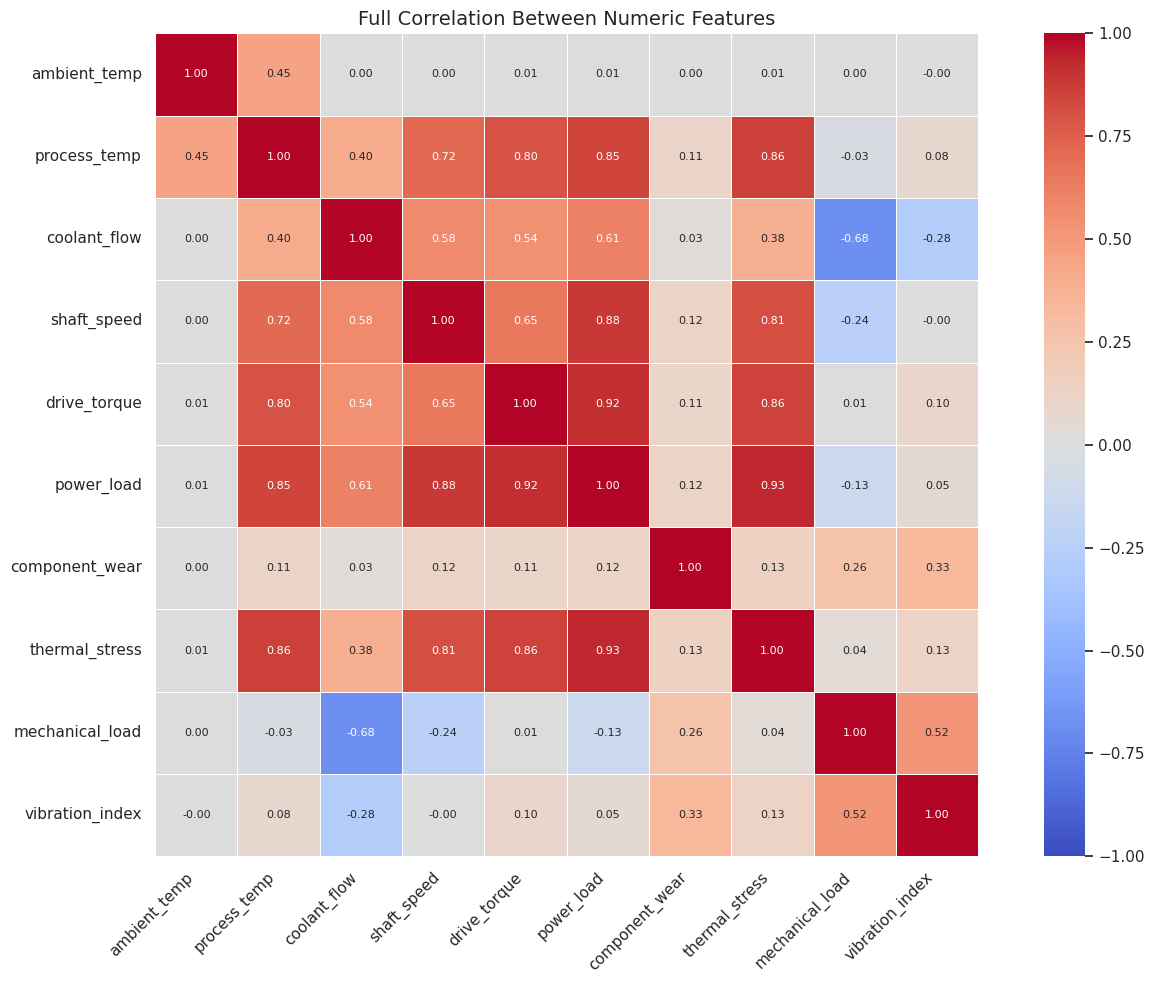

Strongly correlated pairs (|r| > 0.8):


,feature_1,feature_2,correlation
36,power_load,thermal_stress,0.932
30,drive_torque,power_load,0.916
25,shaft_speed,power_load,0.884
14,process_temp,thermal_stress,0.862
32,drive_torque,thermal_stress,0.859
12,process_temp,power_load,0.848
27,shaft_speed,thermal_stress,0.815
11,process_temp,drive_torque,0.803


In [ ]:
# CORRELATION BETWEEN FEATURES

corr = train[num_cols].corr()

# Full correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    annot_kws={"size": 8},
    square=True
)

plt.title("Full Correlation Between Numeric Features", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


# List strongly correlated pairs (|r| > 0.8)
pairs = (
    corr.where(np.triu(np.ones_like(corr, dtype=bool), k=1))
        .stack()
        .reset_index()
)

pairs.columns = ["feature_1", "feature_2", "correlation"]

strong = pairs[
    pairs["correlation"].abs() > 0.8
].sort_values(
    "correlation",
    key=abs,
    ascending=False
)

print("Strongly correlated pairs (|r| > 0.8):")
display(strong.round(3))


Feature ranking with respect to condition:


,feature,MI_score,Rank
0,process_temp,0.2812,1
1,thermal_stress,0.2769,2
2,power_load,0.2282,3
3,drive_torque,0.1892,4
4,shaft_speed,0.1479,5
5,vibration_index,0.1310,6
6,component_wear,0.1205,7
7,mechanical_load,0.1158,8
8,coolant_flow,0.0520,9
9,ambient_temp,0.0425,10


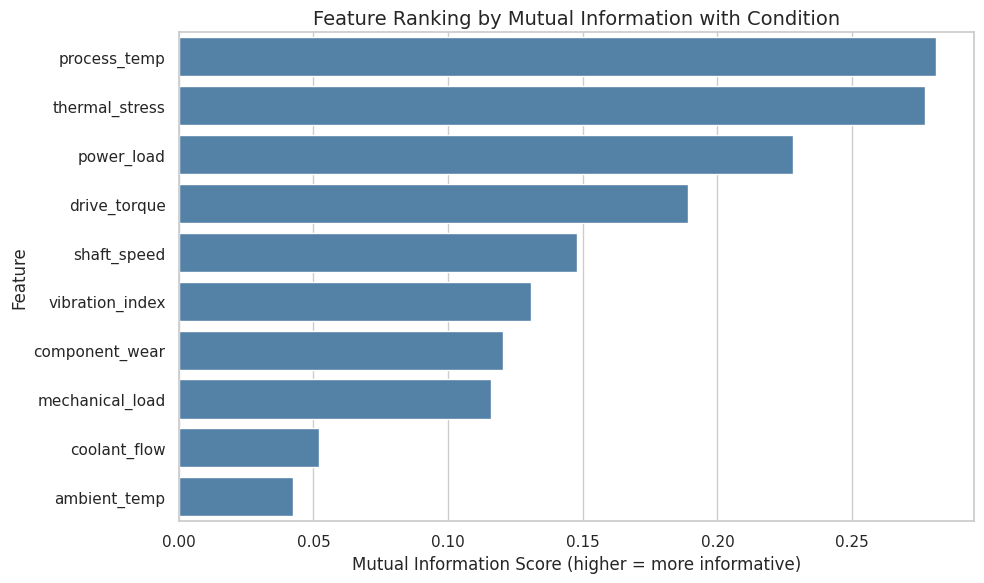

In [ ]:

# ============================================================
# FEATURE RANKING WITH RESPECT TO CONDITION
# Method: Mutual Information (MI)
#
# Higher MI = more information about the target condition.
# Captures nonlinear relationships, unlike ANOVA's mean comparison.
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import mutual_info_classif
from sklearn.impute import SimpleImputer

# Target and features
X = train[num_cols].copy()
y = train["condition"]

# Handle missing values if present
imputer = SimpleImputer(strategy="median")
X_imputed = pd.DataFrame(
    imputer.fit_transform(X),
    columns=num_cols,
    index=X.index
)

# Calculate Mutual Information scores
mi_scores = mutual_info_classif(
    X_imputed,
    y,
    discrete_features=False,
    random_state=42
)

# Create ranking table
mi_df = pd.DataFrame({
    "feature": num_cols,
    "MI_score": mi_scores
}).sort_values(
    "MI_score",
    ascending=False
).reset_index(drop=True)

mi_df["Rank"] = np.arange(1, len(mi_df) + 1)

print("Feature ranking with respect to condition:")
display(mi_df.round(4))


# ============================================================
# BAR PLOT — MOST INFORMATIVE FEATURES FIRST
# ============================================================

plt.figure(figsize=(10, max(6, 0.45 * len(mi_df))))

sns.barplot(
    data=mi_df,
    y="feature",
    x="MI_score",
    color="steelblue"
)

plt.title(
    "Feature Ranking by Mutual Information with Condition",
    fontsize=14
)
plt.xlabel("Mutual Information Score (higher = more informative)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [ ]:

# M1: FEATURES, TARGET AND CROSS-VALIDATION FOLDS
# One KFold object is shared by ALL models and tuning, so every
# model is tested on exactly the same 5 splits (fair comparison).
# 5 folds = data split into 5 parts of 20%. Each part is used once
# for validation while the other 80% trains the model.
# shuffle=True so each fold gets a random mix of rows (in case
# the file is ordered by class).

from sklearn.model_selection import KFold, cross_validate, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
RANDOM_STATE=42

# Final feature list from EDA (unit_id dropped; mech_power removed)
FEATURES = ["unit_type", "ambient_temp", "process_temp", "coolant_flow",
            "shaft_speed", "drive_torque", "power_load", "component_wear",
            "thermal_stress", "mechanical_load", "vibration_index"]

X = train[FEATURES]
y = train["condition"]

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Check: the class mix in each validation fold should be close to 50/25/25
for i, (tr_idx, va_idx) in enumerate(kf.split(X)):
    pct = (y.iloc[va_idx].value_counts(normalize=True).sort_index() * 100).round(1).tolist()
    print(f"Fold {i+1}: train={len(tr_idx)}, val={len(va_idx)}, val class % (0/1/2) = {pct}")

Fold 1: train=12800, val=3200, val class % (0/1/2) = [49.3, 25.1, 25.6]
Fold 2: train=12800, val=3200, val class % (0/1/2) = [50.0, 26.0, 23.9]
Fold 3: train=12800, val=3200, val class % (0/1/2) = [49.4, 25.3, 25.3]
Fold 4: train=12800, val=3200, val class % (0/1/2) = [51.0, 23.6, 25.3]
Fold 5: train=12800, val=3200, val class % (0/1/2) = [50.2, 25.0, 24.8]


Logistic Regression  -> Val Acc: 0.8221
Naive Bayes          -> Val Acc: 0.7649
Decision Tree        -> Val Acc: 0.8101
Random Forest        -> Val Acc: 0.8786
XGBoost              -> Val Acc: 0.8814


,Model,Train Acc,Val Acc,Val Std,Overfit Gap
0,XGBoost,0.9821,0.8814,0.0031,0.1007
1,Random Forest,1.0000,0.8786,0.0036,0.1214
2,Logistic Regression,0.8224,0.8221,0.0049,0.0003
3,Decision Tree,1.0000,0.8101,0.0040,0.1899
4,Naive Bayes,0.7654,0.7649,0.0067,0.0005


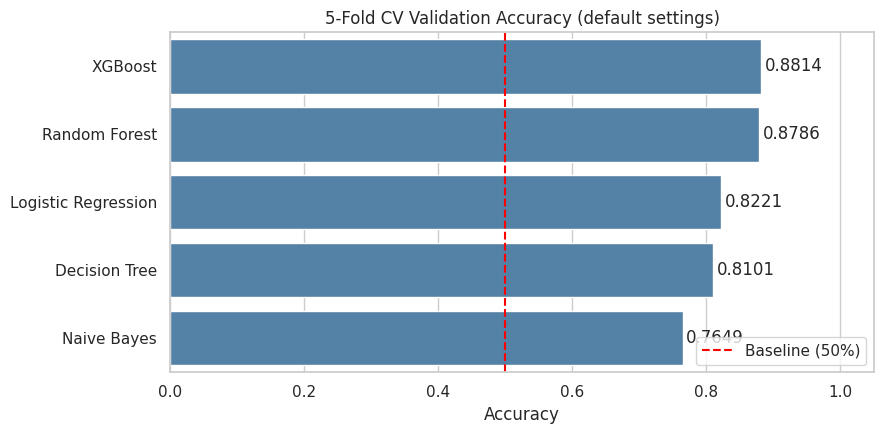

In [ ]:
# ============================================================
# M2: BASELINE MODEL COMPARISON (default settings)
# Each model is trained and validated 5 times (once per fold).
# We record:
#   - Train accuracy: how well it fits data it has seen
#   - Val accuracy:   how well it predicts UNSEEN data (what matters)
#   - Overfit gap:    train - val. A large gap = memorising, not learning.
# Only Logistic Regression is scaled. The scaler is inside a pipeline,
# so it is fitted on the training folds only (no leakage).
# Naive Bayes and tree models don't depend on feature scale.
# ============================================================

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1),
}

results = []
for name, model in models.items():
    cv = cross_validate(model, X, y, cv=kf, scoring="accuracy", return_train_score=True)
    results.append({
        "Model": name,
        "Train Acc": cv["train_score"].mean(),
        "Val Acc": cv["test_score"].mean(),
        "Val Std": cv["test_score"].std(),
    })
    print(f"{name:20s} -> Val Acc: {cv['test_score'].mean():.4f}")

results_df = pd.DataFrame(results)
results_df["Overfit Gap"] = results_df["Train Acc"] - results_df["Val Acc"]
results_df = results_df.sort_values("Val Acc", ascending=False).reset_index(drop=True)
display(results_df.round(4))

# --- Bar chart with the 50% baseline line ---
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=results_df, x="Val Acc", y="Model", color="steelblue")
for i, v in enumerate(results_df["Val Acc"]):
    ax.text(v + 0.005, i, f"{v:.4f}", va="center")
plt.axvline(0.5, color="red", linestyle="--", label="Baseline (50%)")
plt.xlim(0, 1.05)
plt.title("5-Fold CV Validation Accuracy (default settings)")
plt.xlabel("Accuracy")
plt.ylabel("")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [ ]:

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
import pandas as pd

# 1. Define the hyperparameter grid
param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.05, 0.1]
}

# 2. Create and fit the grid search
grid = GridSearchCV(
    estimator=XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric="mlogloss",
        n_jobs=-1
    ),
    param_grid=param_grid,
    cv=kf,
    scoring="accuracy",
    refit=True,
    n_jobs=1,
    verbose=1
)

grid.fit(X, y)

# 3. Evaluate default XGBoost using the same CV splits
xgb_default = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
    n_jobs=-1
)

default_scores = cross_val_score(
    xgb_default, X, y, cv=kf, scoring="accuracy"
)
default_acc = default_scores.mean()

# 4. Compare results
print("\nBest parameters:", grid.best_params_)
print(f"CV accuracy (default XGB): {default_acc:.4f}")
print(f"CV accuracy (tuned XGB):   {grid.best_score_:.4f}")
print(f"Improvement from tuning:   {grid.best_score_ - default_acc:+.4f}")

# 5. Display the top parameter combinations
cv_table = (
    pd.DataFrame(grid.cv_results_)[
        ["param_n_estimators", "param_max_depth",
         "param_learning_rate", "mean_test_score", "std_test_score"]
    ]
    .sort_values("mean_test_score", ascending=False)
    .reset_index(drop=True)
)

display(cv_table.round(4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
CV accuracy (default XGB): 0.8814
CV accuracy (tuned XGB):   0.8863
Improvement from tuning:   +0.0048


,param_n_estimators,param_max_depth,param_learning_rate,mean_test_score,std_test_score
0,300,3,0.10,0.8863,0.0047
1,300,5,0.10,0.8845,0.0030
2,300,5,0.05,0.8840,0.0041
3,100,5,0.10,0.8835,0.0035
4,100,7,0.10,0.8827,0.0026
5,300,7,0.05,0.8822,0.0030
6,300,7,0.10,0.8819,0.0028
7,300,3,0.05,0.8809,0.0019
8,100,7,0.05,0.8808,0.0047
9,100,5,0.05,0.8792,0.0037


In [ ]:
# Always start from the full list, so re-running this cell gives the same result
FEATURES_WITH = ["unit_type", "ambient_temp", "process_temp", "coolant_flow",
                 "shaft_speed", "drive_torque", "power_load", "component_wear",
                 "thermal_stress", "mechanical_load", "vibration_index"]

xgb_check = XGBClassifier(random_state=RANDOM_STATE, eval_metric="mlogloss", n_jobs=-1)

acc_with = cross_val_score(xgb_check, train[FEATURES_WITH], y, cv=kf, scoring="accuracy").mean()

print(f"XGBoost:    {acc_with:.4f}")
X = train[FEATURES]
print(f"Final features ({len(FEATURES)}):", FEATURES)

XGBoost:    0.8814
Final features (11): ['unit_type', 'ambient_temp', 'process_temp', 'coolant_flow', 'shaft_speed', 'drive_torque', 'power_load', 'component_wear', 'thermal_stress', 'mechanical_load', 'vibration_index']


In [ ]:

import numpy as np
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier

best_params = grid.best_params_

xgb_tuned = XGBClassifier(
    **best_params,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
    n_jobs=-1
)

tuned_scores = cross_val_score(
    xgb_tuned, X, y,
    cv=kf,
    scoring="accuracy"
)

print("Tuned XGBoost fold accuracies:",
      np.round(tuned_scores, 4))
print(f"Mean accuracy: {tuned_scores.mean():.4f}")
print(f"Standard deviation: {tuned_scores.std():.4f}")


Tuned XGBoost fold accuracies: [0.8853 0.895  0.8838 0.8809 0.8862]
Mean accuracy: 0.8863
Standard deviation: 0.0047


In [ ]:
from xgboost import XGBClassifier

# Best hyperparameters from GridSearchCV
best_params = grid.best_params_

# Create the final model
final_xgb = XGBClassifier(
    **best_params,
    random_state=RANDOM_STATE,
    eval_metric="mlogloss",
    n_jobs=-1
)

# Train on the entire training dataset
final_xgb.fit(X, y)

print("Final XGBoost model trained successfully!")
print("Hyperparameters:", best_params)
print("Training samples:", X.shape[0])
print("Number of features:", X.shape[1])

Final XGBoost model trained successfully!
Hyperparameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
Training samples: 16000
Number of features: 11


Final model trained successfully.
Training rows: 16000
Number of features: 11
Features: ['unit_type', 'ambient_temp', 'process_temp', 'coolant_flow', 'shaft_speed', 'drive_torque', 'power_load', 'component_wear', 'thermal_stress', 'mechanical_load', 'vibration_index']
Best parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 300}
Best CV accuracy: 0.8863


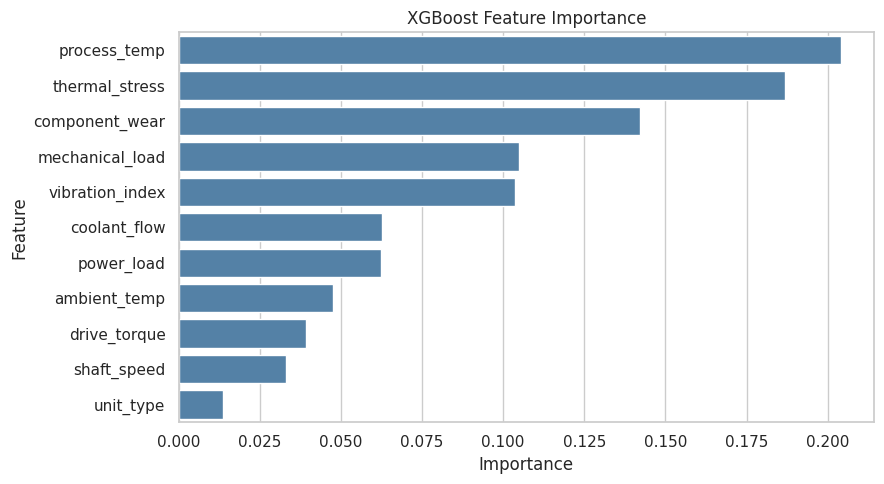

,importance
process_temp,0.2041
thermal_stress,0.1868
component_wear,0.1422
mechanical_load,0.1049
vibration_index,0.1037
coolant_flow,0.0627
power_load,0.0623
ambient_temp,0.0475
drive_torque,0.0393
shaft_speed,0.0330


Number of test predictions: 4000
Predicted classes: [np.int64(0), np.int64(1), np.int64(2)]

Submission shape: (4000, 2)
Submission columns: ['unit_id', 'condition']
Missing predictions: 0

Predicted class distribution (%):
condition
0    53.3
1    23.5
2    23.2
Name: proportion, dtype: float64


,unit_id,condition
0,UNT-184630,0
1,UNT-228473,0
2,UNT-255783,1
3,UNT-119059,2
4,UNT-205559,0


Saved to submission.csv


In [ ]:

# M6: FINAL MODEL AND SUBMISSION

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --------------------------------------------------
# 1. FINAL MODEL
# --------------------------------------------------
# GridSearchCV(refit=True) already fitted the best model
# on all rows passed to grid.fit(X, y).

final_model = grid.best_estimator_

# Use the feature columns that were actually used for training.
FEATURES = list(X.columns)

# Safety checks
assert list(final_model.feature_names_in_) == FEATURES, (
    "Model features do not match X.columns."
)

missing_in_test = [f for f in FEATURES if f not in test.columns]
assert not missing_in_test, f"Test is missing features: {missing_in_test}"

print("Final model trained successfully.")
print("Training rows:", len(X))
print("Number of features:", len(FEATURES))
print("Features:", FEATURES)
print("Best parameters:", grid.best_params_)
print(f"Best CV accuracy: {grid.best_score_:.4f}")

# --------------------------------------------------
# 2. FEATURE IMPORTANCE
# --------------------------------------------------
imp = pd.Series(
    final_model.feature_importances_,
    index=FEATURES
).sort_values(ascending=False)

engineered_features = {"wear_torque", "stress_per_flow"}
colors = [
    "orange" if feature in engineered_features else "steelblue"
    for feature in imp.index
]

plt.figure(figsize=(9, max(5, 0.4 * len(imp))))
sns.barplot(x=imp.values, y=imp.index, hue=imp.index,
            palette=dict(zip(imp.index, colors)),
            legend=False)

plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

display(imp.round(4).to_frame("importance"))

# --------------------------------------------------
# 3. PREDICT ON TEST DATA
# --------------------------------------------------
X_test = test[FEATURES].copy()

test_pred = final_model.predict(X_test).astype(int)

print("Number of test predictions:", len(test_pred))
print("Predicted classes:", sorted(np.unique(test_pred)))

# --------------------------------------------------
# 4. BUILD SUBMISSION
# --------------------------------------------------
# Preserve the exact row order of sample_submission.
pred_df = pd.DataFrame({
    "unit_id": test["unit_id"].to_numpy(),
    "condition": test_pred
})

submission = sample_sub[["unit_id"]].merge(
    pred_df,
    on="unit_id",
    how="left",
    validate="one_to_one",
    sort=False
)

# --------------------------------------------------
# 5. SANITY CHECKS
# --------------------------------------------------
assert len(submission) == len(sample_sub), (
    "Submission row count does not match sample_submission."
)
assert submission["condition"].notna().all(), (
    "Some rows have missing predictions."
)
assert submission["unit_id"].equals(sample_sub["unit_id"]), (
    "Submission unit_id order does not match sample_submission."
)
assert submission["condition"].isin([0, 1, 2]).all(), (
    "Unexpected class values in predictions."
)

print("\nSubmission shape:", submission.shape)
print("Submission columns:", submission.columns.tolist())
print("Missing predictions:", submission["condition"].isna().sum())

print("\nPredicted class distribution (%):")
print(
    (submission["condition"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# --------------------------------------------------
# 6. SAVE SUBMISSION
# --------------------------------------------------
output_path = "submission.csv"
submission.to_csv(output_path, index=False)

display(submission.head())
print(f"Saved to {output_path}")
